# Model 2: DTW + Random Forest

Model 3 averages the MFCCs over time, which throws away the timing of a stutter (the repeats in a
WordRep, the stretched sound in a Prolongation). This model keeps the whole MFCC sequence and
compares clips with dynamic time warping (DTW).

1. Compute the MFCC sequence of every clip (same settings as Model 3).
2. Pick one prototype per class: out of 40 random training clips of that class, the one with the
   smallest total DTW distance to the other 39 (the medoid). Doing this over every training clip
   would need tens of millions of DTW calls.
3. Describe every clip by its DTW distance to each of the 6 prototypes, i.e. 6 numbers per clip.
4. Train the same Random Forest as Model 3 on those 6 numbers, so any difference between the two
   models comes from the features and not the classifier.

Exact DTW is too slow for ~15,000 clips in Python, so this uses
[`fastdtw`](https://github.com/slaypni/fastdtw), an approximate version, spread across all CPU
cores with `joblib`. The first run takes 20-30 minutes on 12 cores. Every step is cached in
`feature_cache/`, so later runs are quick.

In [1]:
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from fastdtw import fastdtw
from joblib import Parallel, delayed
from scipy.spatial.distance import euclidean

%run common.ipynb  # shared settings and helper functions

PROTOTYPE_SAMPLE_SIZE = 40  # clips per class used to find the medoid
DTW_RADIUS = 5              # fastdtw search radius: bigger is closer to exact DTW, but slower

## 1. Labels

Same labels and splits as Model 3 (`load_clips` in `common.ipynb`).

In [2]:
clips = load_clips()
train_df, dev_df, test_df = split_clips(clips)

print(f"Usable clips: {len(clips)}")
print(f"Train: {len(train_df)}, Dev: {len(dev_df)}, Test: {len(test_df)}")
print_class_counts(train_df["label"], "\nTraining set class distribution (before resampling):")

Usable clips: 14930
Train: 8708, Dev: 3001, Test: 3221

Training set class distribution (before resampling):
  0 Prolongation: 762
  1 Block: 814
  2 SoundRep: 543
  3 WordRep: 913
  4 Interjection: 1588
  5 NoStutteredWords: 4088


## 2. MFCC sequences

Same clip extraction and MFCC settings as Model 3, but the full sequence is kept instead of the
average. Every clip is 3 seconds, so every sequence has the same shape: 301 frames x 40 MFCCs.

In [3]:
def mfcc_sequences(clips):
    """One (frames, 40) MFCC sequence per clip. Time comes first because that is what fastdtw expects."""
    return np.stack([mfcc(clip).T.astype(np.float32) for clip in clips])


def sep28k_sequences(df, name):
    return cached(f"Xseq_{name}_dtwseq_v1", f"y_{name}_dtwseq_v1",
                  lambda: (mfcc_sequences(sep28k_clips(df, name)), df["label"].to_numpy()))


seq_train, y_train_full = sep28k_sequences(train_df, "train_full")
seq_dev, y_dev = sep28k_sequences(dev_df, "dev")
seq_test, y_test = sep28k_sequences(test_df, "test")

print(f"\nTrain: {seq_train.shape}, Dev: {seq_dev.shape}, Test: {seq_test.shape}")

Xseq_train_full_dtwseq_v1: loaded from cache
Xseq_dev_dtwseq_v1: loaded from cache


Xseq_test_dtwseq_v1: loaded from cache

Train: (8708, 301, 40), Dev: (3001, 301, 40), Test: (3221, 301, 40)


## 3. Class prototypes

For each class, 40 random training clips are compared with each other (780 DTW calls) and the
medoid becomes that class's prototype. A medoid is a more typical example of the class than a
single randomly chosen clip.

In [4]:
def dtw_distance(a, b, radius=DTW_RADIUS):
    distance, _ = fastdtw(a, b, radius=radius, dist=euclidean)
    return distance


def find_medoid(seqs):
    """Index of the sequence with the smallest total DTW distance to all the others."""
    n = len(seqs)
    pairs = list(combinations(range(n), 2))
    dists = Parallel(n_jobs=-1, verbose=1)(delayed(dtw_distance)(seqs[i], seqs[j]) for i, j in pairs)

    matrix = np.zeros((n, n))
    for (i, j), d in zip(pairs, dists):
        matrix[i, j] = matrix[j, i] = d
    return np.argmin(matrix.sum(axis=1))


def select_prototypes(seqs, labels):
    rng = np.random.default_rng(SEED)
    chosen = []
    for c, name in enumerate(CLASS_NAMES):
        candidates = np.where(labels == c)[0]
        sample = rng.choice(candidates, size=min(PROTOTYPE_SAMPLE_SIZE, len(candidates)), replace=False)
        medoid = sample[find_medoid(seqs[sample])]
        print(f"{name}: prototype is training clip #{medoid}")
        chosen.append(medoid)
    chosen = np.array(chosen)
    return seqs[chosen].astype(np.float32), chosen


prototypes, prototype_indices = cached("prototypes_dtw_v1", "prototype_indices_dtw_v1",
                                       lambda: select_prototypes(seq_train, y_train_full))
print(f"Prototypes: {prototypes.shape}")

prototypes_dtw_v1: loaded from cache
Prototypes: (6, 301, 40)


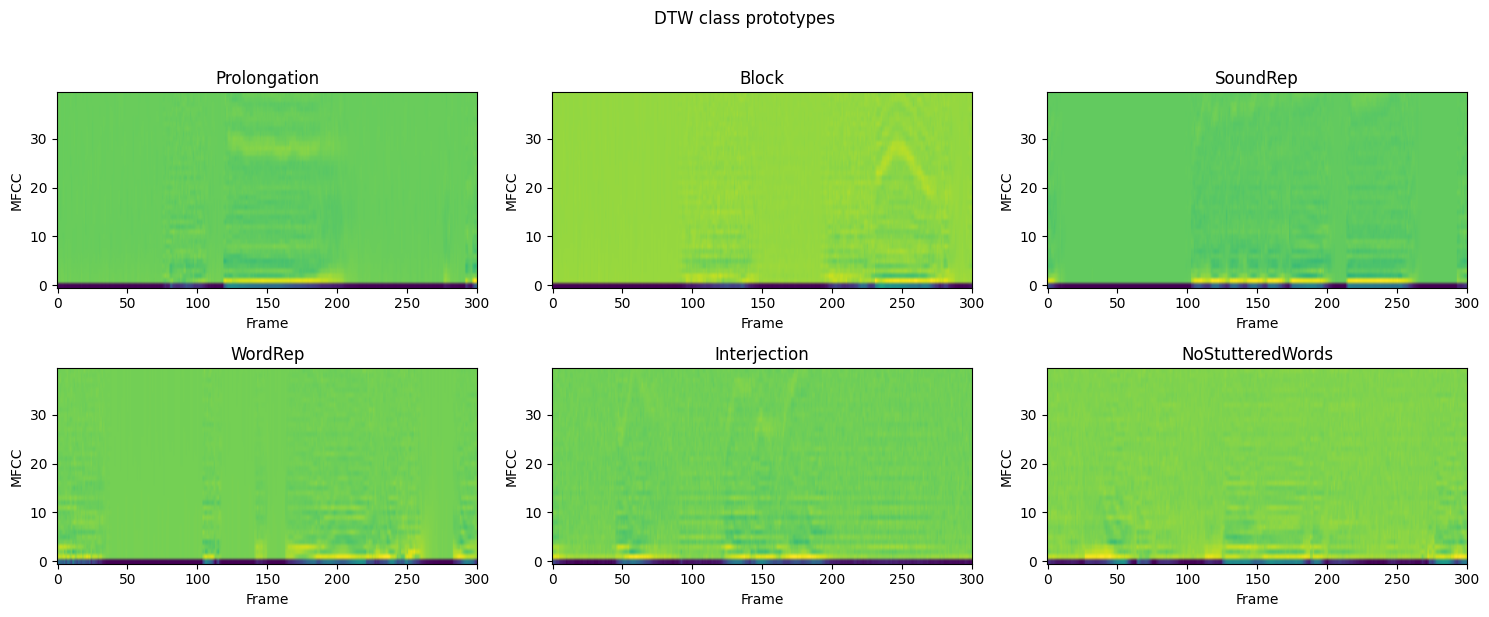

In [5]:
# Sanity check: what each prototype looks like
fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for ax, proto, name in zip(axes.flat, prototypes, CLASS_NAMES):
    ax.imshow(proto.T, aspect="auto", origin="lower", cmap="viridis")
    ax.set_title(name)
    ax.set_xlabel("Frame")
    ax.set_ylabel("MFCC")
plt.suptitle("DTW class prototypes", y=1.02)
plt.tight_layout()
plt.show()

## 4. DTW distance features

Each clip becomes 6 numbers: its DTW distance to each class prototype. That is 6 DTW calls per clip,
run in parallel and cached.

In [6]:
def distances_to_prototypes(seq, prototypes):
    return [dtw_distance(seq, p) for p in prototypes]


def dtw_features(seqs, labels, name):
    def build():
        rows = Parallel(n_jobs=-1, verbose=5)(delayed(distances_to_prototypes)(s, prototypes) for s in seqs)
        return np.array(rows), labels
    return cached(f"X_{name}_dtw_v1", f"y_{name}_dtw_v1", build)

In [7]:
X_train_full, y_train_full = dtw_features(seq_train, y_train_full, "train_full")
X_dev, y_dev = dtw_features(seq_dev, y_dev, "dev")
X_test, y_test = dtw_features(seq_test, y_test, "test")

print(f"\nTrain: {X_train_full.shape}, Dev: {X_dev.shape}, Test: {X_test.shape}")
pd.DataFrame(X_train_full[:5], columns=[f"dtw_to_{n}" for n in CLASS_NAMES])

X_train_full_dtw_v1: loaded from cache
X_dev_dtw_v1: loaded from cache
X_test_dtw_v1: loaded from cache

Train: (8708, 6), Dev: (3001, 6), Test: (3221, 6)


,dtw_to_Prolongation,dtw_to_Block,dtw_to_SoundRep,dtw_to_WordRep,dtw_to_Interjection,dtw_to_NoStutteredWords
0,40748.370672,46348.106966,47167.227038,44402.184054,50914.866281,43784.964815
1,49670.129735,53166.324380,48794.050927,47837.854927,51939.197921,51724.780938
2,59305.280221,69885.272328,63645.138243,53593.514668,47282.740638,58971.626379
3,45878.836166,53798.856909,50311.002800,47592.211556,48252.826589,56611.414977
4,39210.137955,46414.134856,42537.059147,49792.691602,39982.923469,47480.162460


## 5. Choosing the imbalance strategy on dev

Same procedure as Model 3: one forest per strategy, scored by macro F1 on dev, best one kept.

In [8]:
strategies = imbalance_strategies(y_train_full)
forests, strategy_dev_f1 = {}, {}

for name, idx in strategies.items():
    forest = make_random_forest().fit(X_train_full[idx], y_train_full[idx])
    forests[name] = forest
    strategy_dev_f1[name] = macro_f1(y_dev, forest.predict(X_dev))
    print(f"{name:15s} n_train={len(idx):6d}  dev macro F1={strategy_dev_f1[name]:.4f}")

best_strategy = max(strategy_dev_f1, key=strategy_dev_f1.get)
rf = forests[best_strategy]
print(f"\nBest strategy on dev: {best_strategy}")

class_weighted  n_train=  8708  dev macro F1=0.1525


undersampling   n_train=  5544  dev macro F1=0.1679


oversampling    n_train= 24528  dev macro F1=0.1675

Best strategy on dev: undersampling


## 6. Evaluate

=== Dev ===
                  precision    recall  f1-score   support

    Prolongation       0.11      0.16      0.13       251
           Block       0.13      0.14      0.14       291
        SoundRep       0.11      0.11      0.11       200
         WordRep       0.11      0.15      0.13       349
    Interjection       0.18      0.42      0.26       503
NoStutteredWords       0.50      0.17      0.25      1407

        accuracy                           0.20      3001
       macro avg       0.19      0.19      0.17      3001
    weighted avg       0.31      0.20      0.21      3001

Macro AUC-ROC (OVR): 0.5413


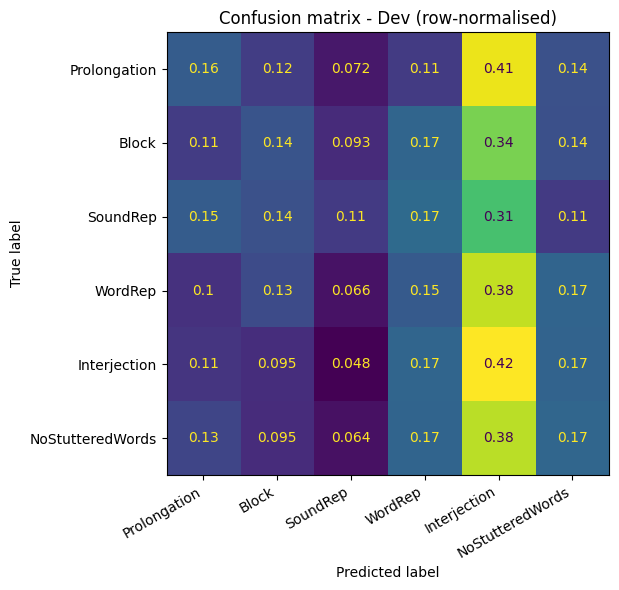

In [9]:
def evaluate(X, y, title):
    report(y, rf.predict(X), rf.predict_proba(X), title)


evaluate(X_dev, y_dev, "Dev")

=== Test ===
                  precision    recall  f1-score   support

    Prolongation       0.11      0.17      0.13       242
           Block       0.15      0.17      0.16       310
        SoundRep       0.04      0.04      0.04       178
         WordRep       0.15      0.18      0.16       445
    Interjection       0.18      0.42      0.25       532
NoStutteredWords       0.53      0.20      0.29      1514

        accuracy                           0.22      3221
       macro avg       0.19      0.20      0.17      3221
    weighted avg       0.33      0.22      0.23      3221

Macro AUC-ROC (OVR): 0.5473


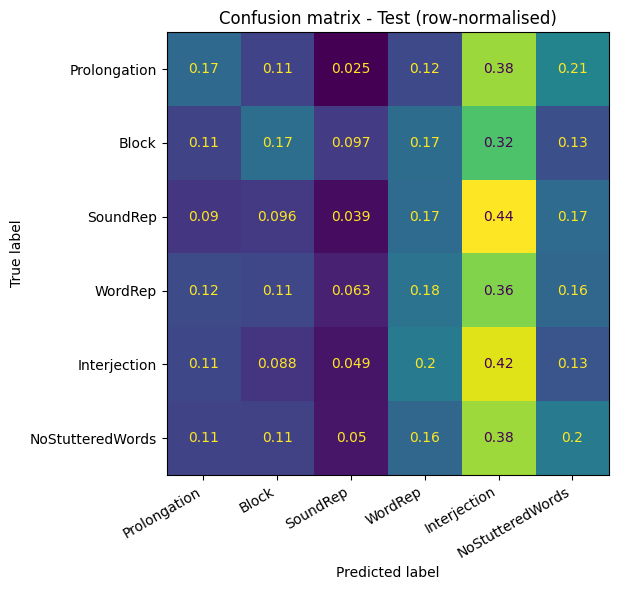

In [10]:
evaluate(X_test, y_test, "Test")

## 7. Cross-corpus test on UCLASS

UCLASS clips go through the same steps, using the prototypes picked from the SEP-28k-E training set.
No UCLASS clip was used for training, prototype selection or choosing the strategy.

Xseq_uclass_dtwseq_v1: loaded from cache
X_uclass_dtw_v1: loaded from cache
UCLASS: 4712 clips
age_group
Adult (18+)    3625
Child (<18)    1087
Name: count, dtype: int64
=== UCLASS ===
                  precision    recall  f1-score   support

    Prolongation       0.05      0.16      0.08       443
           Block       0.24      0.08      0.12      1132
        SoundRep       0.11      0.08      0.09       720
         WordRep       0.01      0.11      0.02        54
    Interjection       0.04      0.43      0.08       141
NoStutteredWords       0.51      0.13      0.21      2222

        accuracy                           0.12      4712
       macro avg       0.16      0.16      0.10      4712
    weighted avg       0.32      0.12      0.15      4712

Macro AUC-ROC (OVR): 0.5024


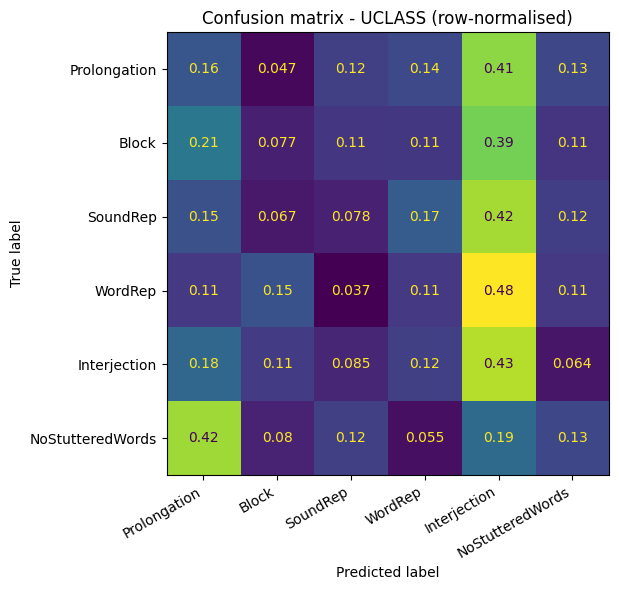

In [11]:
uclass_meta = load_uclass_meta()
seq_uclass, y_uclass = cached("Xseq_uclass_dtwseq_v1", "y_uclass_dtwseq_v1",
                              lambda: (mfcc_sequences(uclass_clips(uclass_meta)), uclass_meta["label"].to_numpy()))
assert len(uclass_meta) == len(y_uclass), "rerun UCLASS_Preprocessing.ipynb"

X_uclass, y_uclass = dtw_features(seq_uclass, y_uclass, "uclass")
print(f"UCLASS: {len(y_uclass)} clips")
print(uclass_meta["age_group"].value_counts())
evaluate(X_uclass, y_uclass, "UCLASS")

## 8. Child vs adult

Same as Model 3: macro F1 per age group with a 95% bootstrap CI. Child results are exploratory
because there are fewer than 20 child speakers.

In [12]:
age_group_report(y_uclass, rf.predict(X_uclass), uclass_meta)


=== UCLASS - Child (<18) (n=1087) ===
                  precision    recall  f1-score   support

    Prolongation       0.11      0.18      0.14       150
           Block       0.27      0.16      0.20       270
        SoundRep       0.17      0.12      0.14       236
         WordRep       0.02      0.05      0.03        38
    Interjection       0.10      0.40      0.15        70
NoStutteredWords       0.21      0.08      0.11       323

        accuracy                           0.14      1087
       macro avg       0.15      0.17      0.13      1087
    weighted avg       0.19      0.14      0.14      1087



Macro F1: 0.1295  (95% bootstrap CI: [0.1102, 0.1496])

=== UCLASS - Adult (18+) (n=3625) ===
                  precision    recall  f1-score   support

    Prolongation       0.04      0.14      0.06       293
           Block       0.22      0.05      0.08       862
        SoundRep       0.08      0.06      0.07       484
         WordRep       0.01      0.25      0.02        16
    Interjection       0.03      0.46      0.05        71
NoStutteredWords       0.60      0.14      0.23      1899

        accuracy                           0.12      3625
       macro avg       0.16      0.18      0.09      3625
    weighted avg       0.38      0.12      0.15      3625



Macro F1: 0.0856  (95% bootstrap CI: [0.0774, 0.0942])


## 9. Save predictions

Used by `Results_Summary.ipynb` to compare the three models without retraining.

In [13]:
splits = {name: (y, rf.predict(X), rf.predict_proba(X))
          for name, X, y in [("dev", X_dev, y_dev), ("test", X_test, y_test), ("uclass", X_uclass, y_uclass)]}
save_predictions("model2_dtw_rf_preds.npz", splits, strategy_dev_f1, best_strategy)

Saved results\model2_dtw_rf_preds.npz

## Comparison with Models 1 and 3

Model 2 vs Model 3 tests whether keeping the timing of the MFCCs helps, using the same classifier
for both. The side-by-side numbers and significance tests are in `Results_Summary.ipynb`.